# Figs. 5, A2, and A3: carbon cycle response to perturbations

In [1]:
from helpers import *
import matplotlib as mpl
import matplotlib.lines as mlines
import box_model
import gcm_model

V_C = 8.5   # volcanic outgassing at wsum=1 [Emol/Myr]
n = 0.5     # weathering feedback exponent
alpha = 2 * n

# background carbon inventory N_b(t) and weathering W_b(t) from the 720 Ma (Mer21), no-OHT GCM runs
stats = compute_stats("default", "720Ma_Mer21")
t_bg = stats["age"]
order = np.argsort(t_bg)
t_asc = t_bg[order]
Nb_asc = carbon_inventory(stats["background"]["co2"])[order]
Wb_asc = stats["background"]["wsum"][order]

def Nb_geologic(t_gyr):
    return np.interp(t_gyr, t_asc, Nb_asc)

def V_geologic(t_gyr):
    return V_C * np.interp(t_gyr, t_asc, Wb_asc)

thetas = [0.01, 0.1, 1.0] # perturbation decay rates [1/Myr]
colors = ["tab:blue", "tab:orange", "tab:green"]
t_eval = np.linspace(0, 3, 7) # epochs for numerical runs [Gyr before present]

### Box model runs and Fig. 5 trajectories

In [2]:
F0 = 1.0 # perturbation amplitude [Emol/Myr]
t_geo = np.linspace(0, 3, 1000)
Nb_arr = Nb_geologic(t_geo)
V_arr = V_geologic(t_geo)
k_arr = alpha * V_arr / Nb_arr

# box model at each epoch: peak excursion, and the run length used for the GCM-coupled runs below
nu_max_num, t_run = {}, {}
for theta in thetas:
    out = [box_model.numerical_nu_max_exp(float(Nb_geologic(t)), float(V_geologic(t)), theta, F0, n) for t in t_eval]
    nu_max_num[theta] = np.array([o[0] for o in out])
    t_run[theta] = np.array([o[1] for o in out])

# GCM-coupled trajectories at each epoch
theta_epoch = 0.1
gcm_data = load_grid("default", "720Ma_Mer21")
trajectories = {}
for t in t_eval:
    res = gcm_model.run_model(gcm_data, F_solar(t), C_imb=F0, theta=theta_epoch, dt=0.005, t_max=15.0)
    trajectories[t] = {"t": np.concatenate([[-1.0], res["t"]]), "N": np.concatenate([[res["N"][0]], res["N"]]),
                       "N0": res["N0"]}

# epoch colors: present = dark red, oldest = pale yellow
cmap = mpl.colormaps["YlOrRd_r"]
norm = mpl.colors.Normalize(vmin=0, vmax=3)
def epoch_color(t_gya):
    return cmap(norm(t_gya))

### GCM-coupled runs for Figs. 5 and A3

In [3]:
band_data = band_means("default", "720Ma_Mer21")

def gcm_nu_max(t_gyr, theta, t_max, lip_band=None):
    res = gcm_model.run_model(gcm_data, F_solar(t_gyr), C_imb=F0, theta=theta, dt=0.01, t_max=t_max,
                              lip_band=lip_band, band_data=band_data)
    return float(np.max(np.abs(res["N"] - res["N0"])) / res["N0"])

# LIP forcing modulated by the local weathering response in each latitude band (None = no latitude dependence)
lat_bands = {"None": None, "Equatorial": "equatorial", "Mid Latitudes": "mid_latitude", "Polar": "polar"}
nu_max_band = {}
for label, band in lat_bands.items():
    nu_max_band[label] = {}
    for theta in thetas:
        nu_max_band[label][theta] = np.array([gcm_nu_max(t, theta, tr, lip_band=band) for t, tr in zip(t_eval, t_run[theta])])

### Fig. 5

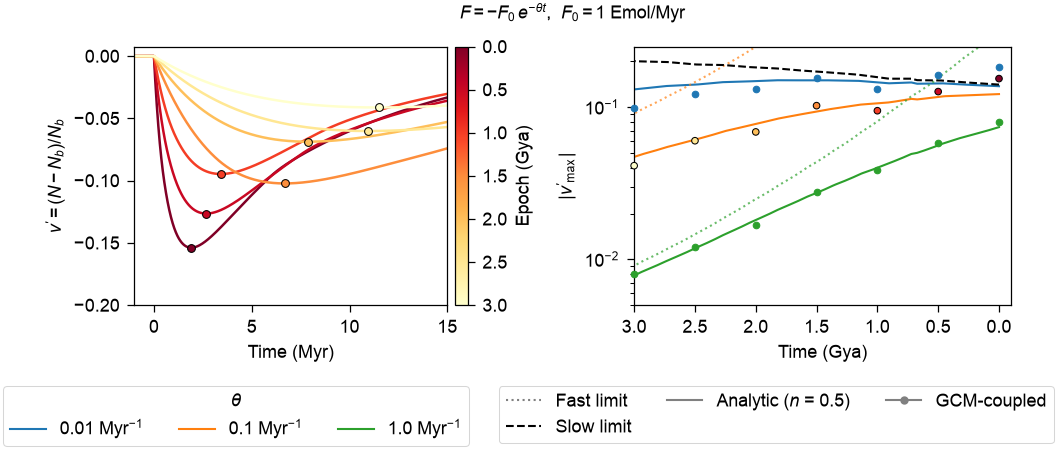

In [4]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(FULL_WIDTH, ROW_HEIGHT))

# trajectories
for t, traj in trajectories.items():
    nu = (traj["N"] - traj["N0"]) / traj["N0"]
    ax_a.plot(traj["t"], nu, color=epoch_color(t), lw=1.2)
    i = np.argmin(nu)
    ax_a.scatter([traj["t"][i]], [nu[i]], color=epoch_color(t), s=14, edgecolor="k", linewidth=0.5, zorder=5)
ax_a.set_xlabel("Time (Myr)")
ax_a.set_ylabel(r"$\nu' = (N-N_b)/N_b$")
ax_a.set_xlim(-1, 15)
ax_a.set_ylim(-0.2, ax_a.get_ylim()[1])
cbar = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax_a, ticks=t_eval, pad=0.02)
cbar.set_label("Epoch (Gya)")
cbar.ax.invert_yaxis()

# |nu'_max|: GCM-coupled runs (as in the left panel) against the analytic solution for n = 0.5
for theta, color in zip(thetas, colors):
    ax_b.plot(t_geo, box_model.nu_max_exp(k_arr, theta, F0, alpha, V_arr), color=color)
    ax_b.plot(t_geo, F0 / (Nb_arr * theta), color=color, ls=":", alpha=0.7)
    if theta == theta_epoch:
        ax_b.scatter(t_eval, nu_max_band["None"][theta], color=[epoch_color(t) for t in t_eval], s=10, edgecolor="k", linewidth=0.5,
                     zorder=5, clip_on=False)
    else:
        ax_b.scatter(t_eval, nu_max_band["None"][theta], color=color, s=10, zorder=4, clip_on=False)
ax_b.plot(t_geo, F0 / (alpha * V_arr), color="k", ls="--")
setup_time_ax(ax_b)
ax_b.set_ylabel(r"$|\nu'_{\max}|$")
ax_b.set_ylim(5e-3, 2.5e-1)
ax_b.set_yscale("log")

plt.tight_layout()

# legends below the axes
leg_theta = fig.legend(handles=[mlines.Line2D([], [], color=c) for c in colors], labels=[rf"${v}$ Myr$^{{-1}}$" for v in thetas],
                       title=r"$\theta$", loc="upper center", ncol=3)
leg_style = fig.legend(handles=[
        mlines.Line2D([], [], color="gray", ls=":", label="Fast limit"),
        mlines.Line2D([], [], color="k", ls="--", label="Slow limit"),
        mlines.Line2D([], [], color="gray", ls="-", label="Analytic ($n$ = 0.5)"),
        mlines.Line2D([], [], color="gray", marker="o", ms=3, label="GCM-coupled"),
    ], loc="upper center", ncol=3)
place_legends_below(fig, [leg_theta, leg_style])

# title centered over the axes, not the legends
fig.canvas.draw()
x0 = min(ax_a.get_window_extent().x0, ax_b.get_window_extent().x0)
x1 = max(ax_a.get_window_extent().x1, ax_b.get_window_extent().x1)
center_x = fig.transFigure.inverted().transform(((x0 + x1) / 2, 0))[0]
title = fig.suptitle(r"$F = -F_0\,e^{-\theta t}$,  $F_0 = 1$ Emol/Myr", x=center_x, y=1.05)

plt.savefig("figs/numax_trajectories.pdf", bbox_inches="tight", bbox_extra_artists=[leg_theta, leg_style, title])
plt.show()

### Fig. A2: sensitivity to the weathering feedback exponent $n$

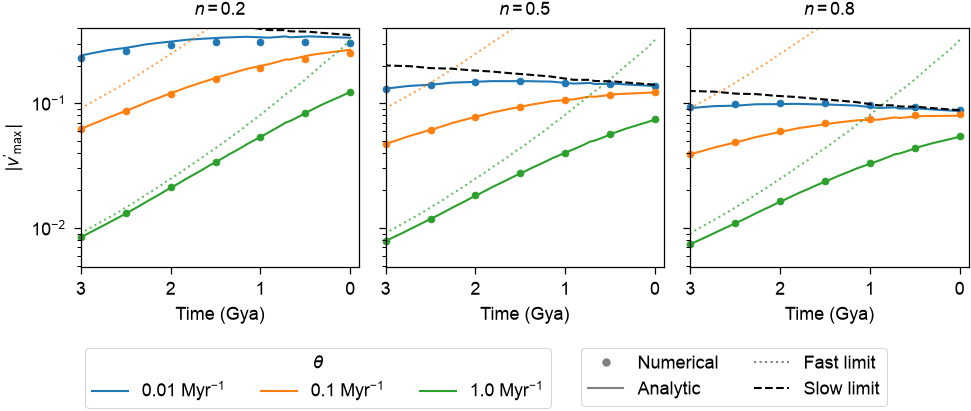

In [5]:
n_values = [0.2, 0.5, 0.8]

nu_max_num_n = {}
for theta in thetas:
    for n_val in n_values:
        nu_max_num_n[(theta, n_val)] = np.array([box_model.numerical_nu_max_exp(float(Nb_geologic(t)), float(V_geologic(t)), theta, F0, n_val)[0]
                                                 for t in t_eval])

fig, axes = plt.subplots(1, 3, figsize=(FULL_WIDTH, ROW_HEIGHT), sharey=True)

for ax, n_val in zip(axes, n_values):
    k_n = 2 * n_val * V_arr / Nb_arr
    for theta, color in zip(thetas, colors):
        ax.scatter(t_eval, nu_max_num_n[(theta, n_val)], color=color, s=10, clip_on=False)
        ax.plot(t_geo, box_model.nu_max_exp(k_n, theta, F0, 2 * n_val, V_arr), color=color)
        ax.plot(t_geo, F0 / (Nb_arr * theta), color=color, ls=":", alpha=0.7)
    ax.plot(t_geo, F0 / (2 * n_val * V_arr), color="k", ls="--")
    setup_time_ax(ax)
    ax.set_title(f"$n = {n_val}$")
    ax.set_yscale("log")

axes[0].set_ylabel("|$\\nu'_{\\max}$|")
axes[0].set_ylim(top=1.3 * max(v.max() for v in nu_max_num_n.values())) # shared across all three panels
plt.tight_layout()

# legends below the panels
leg_theta = fig.legend(handles=[mlines.Line2D([], [], color=c) for c in colors], labels=[rf"${v}$ Myr$^{{-1}}$" for v in thetas],
                       title=r"$\theta$", loc="upper center", ncol=3)
leg_style = fig.legend(handles=[
        mlines.Line2D([], [], color="gray", marker="o", ms=3, ls="none", label="Numerical"),
        mlines.Line2D([], [], color="gray", ls="-", label="Analytic"),
        mlines.Line2D([], [], color="gray", ls=":", label="Fast limit"),
        mlines.Line2D([], [], color="k", ls="--", label="Slow limit"),
    ], loc="upper center", ncol=2)
place_legends_below(fig, [leg_theta, leg_style])

plt.savefig("figs/numax_exp_n_sensitivity.pdf", bbox_inches="tight", bbox_extra_artists=[leg_theta, leg_style])
plt.show()

### Fig. A3: latitude-dependent LIP forcing

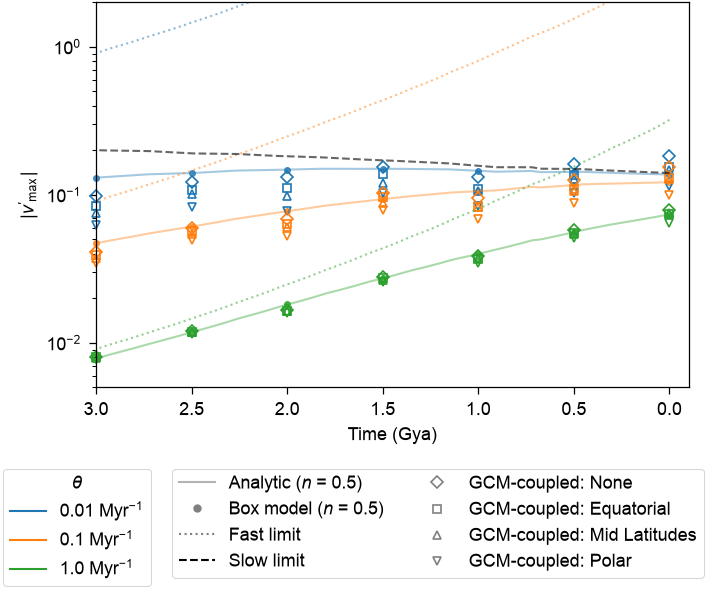

In [6]:
band_markers = {"None": "D", "Equatorial": "s", "Mid Latitudes": "^", "Polar": "v"}

fig, ax = plt.subplots(figsize=(MEDIUM_WIDTH, MEDIUM_HEIGHT))
for theta, color in zip(thetas, colors):
    ax.plot(t_geo, box_model.nu_max_exp(k_arr, theta, F0, alpha, V_arr), color=color, alpha=0.4)
    ax.scatter(t_eval, nu_max_num[theta], color=color, s=8, alpha=0.8, clip_on=False)
    ax.plot(t_geo, F0 / (Nb_arr * theta), color=color, ls=":", alpha=0.5)
    for label, marker in band_markers.items():
        ax.plot(t_eval, nu_max_band[label][theta], color=color, marker=marker, ms=4, mfc="none", mew=0.8, ls="none",
                clip_on=False)
ax.plot(t_geo, F0 / (alpha * V_arr), color="k", ls="--", alpha=0.6)

setup_time_ax(ax)
ax.set_ylabel("|$\\nu'_{\\max}$|")
ax.set_ylim([5e-3, 2])
ax.set_yscale("log")
plt.tight_layout()

# legends below the axes: theta, then line and marker styles
leg_theta = fig.legend(handles=[mlines.Line2D([], [], color=c) for c in colors], labels=[rf"${v}$ Myr$^{{-1}}$" for v in thetas],
                       title=r"$\theta$", loc="upper center")
leg_style = fig.legend(handles=[
        mlines.Line2D([], [], color="gray", alpha=0.6, label="Analytic ($n$ = 0.5)"),
        mlines.Line2D([], [], color="gray", marker="o", ms=3, ls="none", label="Box model ($n$ = 0.5)"),
        mlines.Line2D([], [], color="gray", ls=":", label="Fast limit"),
        mlines.Line2D([], [], color="k", ls="--", label="Slow limit"),
    ] + [mlines.Line2D([], [], color="gray", marker=m, ms=4, ls="none", mfc="none", mew=0.8, label=f"GCM-coupled: {label}")
         for label, m in band_markers.items()],
    loc="upper center", ncol=2)
place_legends_below(fig, [leg_theta, leg_style])

plt.savefig("figs/numax_exp_lat_bands.pdf", bbox_inches="tight", bbox_extra_artists=[leg_theta, leg_style])
plt.show()

### Check: sinusoidal perturbation

Steady-state $|\nu'_{\max}|$ for $F = -F_0\cos(\omega t)$ (not shown in the paper): box model after the transient has decayed, against the linearized solution $F_0/(N_b\sqrt{k^2 + \omega^2})$, which has the same fast ($F_0/(N_b \omega)$) and slow ($F_0/(2nV)$) limits as the exponential case.

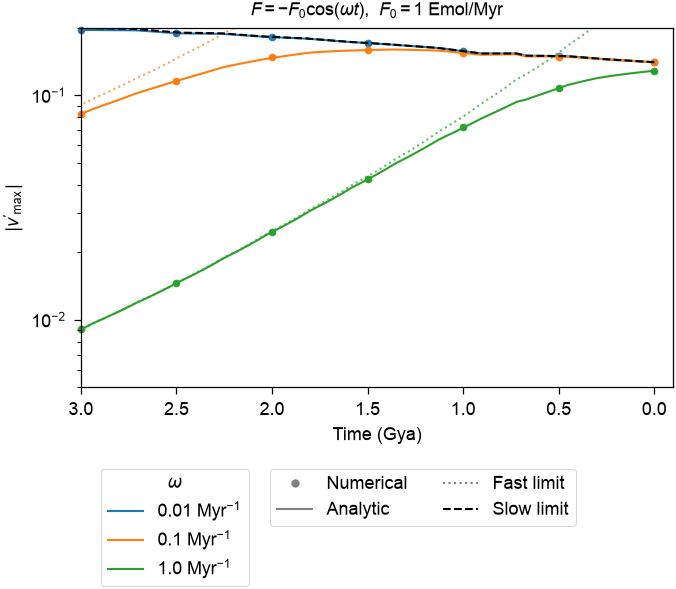

In [7]:
omegas = [0.01, 0.1, 1.0] # forcing frequencies [1/Myr]

def numerical_nu_max_sin(Nb, V, omega):
    # amplitude of nu' over two forcing periods, after a 5/k spin-up for the transient to decay
    k = alpha * V / Nb
    period = 2 * np.pi / omega
    t_spin = 5 / k
    res = box_model.run_model(dt=min(0.01, period / 50), t_max=t_spin + 2 * period, N0=Nb, V_C=V, n=n,
                              f_fn=lambda t: -F0 * np.cos(omega * t))
    tail = res["t"] >= t_spin
    return float(np.max(np.abs(res["N"][tail] - Nb)) / Nb)

nu_max_sin = {}
for omega in omegas:
    nu_max_sin[omega] = np.array([numerical_nu_max_sin(float(Nb_geologic(t)), float(V_geologic(t)), omega) for t in t_eval])

fig, ax = plt.subplots(figsize=(MEDIUM_WIDTH, MEDIUM_HEIGHT))
for omega, color in zip(omegas, colors):
    ax.plot(t_geo, F0 / Nb_arr / np.sqrt(k_arr**2 + omega**2), color=color)
    ax.plot(t_geo, F0 / (Nb_arr * omega), color=color, ls=":", alpha=0.7)
    ax.scatter(t_eval, nu_max_sin[omega], color=color, s=10, clip_on=False)
ax.plot(t_geo, F0 / (alpha * V_arr), color="k", ls="--")
setup_time_ax(ax)
ax.set_ylabel("|$\\nu'_{\\max}$|")
ax.set_title(r"$F = -F_0\cos(\omega t)$,  $F_0 = 1$ Emol/Myr")
ax.set_ylim(5e-3, 2e-1)
ax.set_yscale("log")
plt.tight_layout()

# legends below the axes
leg_omega = fig.legend(handles=[mlines.Line2D([], [], color=c) for c in colors], labels=[rf"${v}$ Myr$^{{-1}}$" for v in omegas],
                       title=r"$\omega$", loc="upper center")
leg_style = fig.legend(handles=[
        mlines.Line2D([], [], color="gray", marker="o", ms=3, ls="none", label="Numerical"),
        mlines.Line2D([], [], color="gray", ls="-", label="Analytic"),
        mlines.Line2D([], [], color="gray", ls=":", label="Fast limit"),
        mlines.Line2D([], [], color="k", ls="--", label="Slow limit"),
    ], loc="upper center", ncol=2)
place_legends_below(fig, [leg_omega, leg_style])
plt.show()